In [1]:
# ✅ Cell 1 — Upload ZIP/CSV, stage as DATA_CSV, and preview 5 head + 5 tail
import os, io, zipfile, shutil
from pathlib import Path
import pandas as pd

# === Setup working dirs (Colab-friendly; falls back if not in Colab)
def get_base_dir():
    for p in [Path("/content"), Path("/mnt/data")]:
        try:
            test = p / "_write_test"
            test.write_text("ok", encoding="utf-8")
            test.unlink(missing_ok=True)
            return p
        except Exception:
            continue
    return Path.cwd()

BASE_DIR = get_base_dir()
RAW_DIR  = BASE_DIR / "data_raw"
OUT_DIR  = BASE_DIR / "data"
RAW_DIR.mkdir(exist_ok=True, parents=True)
OUT_DIR.mkdir(exist_ok=True, parents=True)

# --- Colab upload helper
def _upload():
    try:
        from google.colab import files
        print("📤 Upload your .zip (preferred) or .csv file…")
        up = files.upload()
        if not up:
            raise RuntimeError("No file uploaded.")
        fname = list(up.keys())[0]
        with open(RAW_DIR / fname, "wb") as f:
            f.write(up[fname])
        print(f"✅ Uploaded: {fname} ({len(up[fname]):,} bytes)")
        return str(RAW_DIR / fname)
    except Exception:
        print("ℹ️ If not in Colab, place your file under:", RAW_DIR)
        return None

uploaded_path = _upload()

# --- Stage the main CSV
def stage_csv(uploaded_path: str | None) -> str | None:
    if uploaded_path is None:
        return None
    p = Path(uploaded_path)
    if p.suffix.lower() == ".csv":
        staged = OUT_DIR / "dataset.csv"
        if staged.exists():
            staged.unlink()
        shutil.copy2(p, staged)
        return str(staged)
    if p.suffix.lower() == ".zip":
        with zipfile.ZipFile(p, 'r') as zf:
            zf.extractall(RAW_DIR / "unzipped")
        csvs = list((RAW_DIR / "unzipped").rglob("*.csv"))
        if not csvs:
            raise RuntimeError("No CSV files found in ZIP.")
        best = max(csvs, key=lambda x: x.stat().st_size)
        staged = OUT_DIR / "dataset.csv"
        if staged.exists():
            staged.unlink()
        shutil.copy2(best, staged)
        print(f"📦 Found {len(csvs)} CSV(s) in ZIP. Using largest: {best.name} ({best.stat().st_size:,} bytes)")
        return str(staged)
    raise RuntimeError("Unsupported file type. Please upload .zip or .csv")

DATA_CSV = stage_csv(uploaded_path)

# --- Helpers to preview head/tail efficiently
def read_csv_head(path, n=5):
    return pd.read_csv(path, nrows=n, dtype=str, engine="python", on_bad_lines="skip")

def read_csv_tail(path, n=5, encoding="utf-8"):
    # Read last N data lines without loading whole file
    header = None
    with open(path, "r", encoding=encoding, errors="ignore") as f:
        header = f.readline().rstrip("\n")
    # Read from end in binary chunks until we have >= n non-empty lines
    chunk_size = 256 * 1024
    data = b""
    with open(path, "rb") as fb:
        fb.seek(0, os.SEEK_END)
        file_size = fb.tell()
        pos = file_size
        lines = []
        while pos > 0 and len(lines) <= n:
            read_size = min(chunk_size, pos)
            fb.seek(pos - read_size, os.SEEK_SET)
            data = fb.read(read_size) + data
            pos -= read_size
            lines = data.split(b"\n")
        # Last element may be partial; take last n complete lines ignoring header
        # Decode safely and filter out empty lines
        decoded = [ln.decode(encoding, errors="ignore") for ln in lines]
        # Drop possible duplicated header if we read from the beginning
        tail_lines = [ln for ln in decoded if ln.strip()]
        # Remove header line if present among tail slice
        tail_data = [ln for ln in tail_lines if ln.strip() != header]
        tail_last_n = tail_data[-n:] if len(tail_data) >= n else tail_data
        csv_buf = io.StringIO(header + "\n" + "\n".join(tail_last_n))
        return pd.read_csv(csv_buf, dtype=str, engine="python", on_bad_lines="skip")

if DATA_CSV:
    file_size = Path(DATA_CSV).stat().st_size
    print(f"\n✅ Staged CSV: {DATA_CSV}  ({file_size:,} bytes)")
    head5 = read_csv_head(DATA_CSV, 5)
    tail5 = read_csv_tail(DATA_CSV, 5)
    print("\n🔹 Head (5 rows):")
    display(head5)
    print("\n🔹 Tail (5 rows):")
    display(tail5)
    print("\n🧱 Columns detected:", list(head5.columns))
else:
    print(f"📂 Put your ZIP/CSV under: {RAW_DIR} and rerun this cell.")


📤 Upload your .zip (preferred) or .csv file…


Saving merged (2)http.zip to merged (2)http.zip
✅ Uploaded: merged (2)http.zip (10,437,175 bytes)
📦 Found 1 CSV(s) in ZIP. Using largest: merged (2).csv (212,971,800 bytes)

✅ Staged CSV: /content/data/dataset.csv  (212,971,800 bytes)

🔹 Head (5 rows):


,@timestamp,http.request.method,http.response.status_code,http.version,http.response.body.bytes,user_agent.original,url.path,url.domain,destination.ip,destination.port,source.ip
0,"Sep 20, 2025 @ 11:59:59.895",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.91,172.16.60.2,"8,080",10.10.10.69
1,"Sep 20, 2025 @ 11:59:59.866",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.92,172.16.60.2,"8,080",192.168.10.11
2,"Sep 20, 2025 @ 11:59:59.816",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.92,172.16.60.2,"8,080",192.168.10.13
3,"Sep 20, 2025 @ 11:59:59.802",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.92,172.16.60.2,"8,080",192.168.10.13
4,"Sep 20, 2025 @ 11:59:59.588",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.91,172.16.60.2,"8,080",10.10.10.69



🔹 Tail (5 rows):


,@timestamp,http.request.method,http.response.status_code,http.version,http.response.body.bytes,user_agent.original,url.path,url.domain,destination.ip,destination.port,source.ip
0,"Oct 7, 2025 @ 09:08:03.073",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,10.10.10.60
1,"Oct 7, 2025 @ 09:08:02.998",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,10.10.10.60
2,"Oct 7, 2025 @ 09:08:02.998",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,10.10.10.60
3,"Oct 7, 2025 @ 09:08:02.997",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,10.10.10.60
4,"Oct 7, 2025 @ 09:08:02.997",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,10.10.10.60



🧱 Columns detected: ['@timestamp', 'http.request.method', 'http.response.status_code', 'http.version', 'http.response.body.bytes', 'user_agent.original', 'url.path', 'url.domain', 'destination.ip', 'destination.port', 'source.ip']


In [2]:
# ✅ Cell 2 — Build features (status_class, uri_len, ua_group), light cleaning, preview head/tail (5)
import re
import pandas as pd

assert 'DATA_CSV' in globals() and DATA_CSV is not None, "DATA_CSV not set. Run Cell 1 first."

# --- Read full CSV (all 11 columns as strings; we will type-cast selected ones)
df = pd.read_csv(DATA_CSV, dtype=str, engine="python", on_bad_lines="skip")

# Ensure columns exist (exact names from your sample)
expected_cols = [
    "@timestamp",
    "http.request.method",
    "http.response.status_code",
    "http.version",
    "http.response.body.bytes",
    "user_agent.original",
    "url.path",
    "url.domain",
    "destination.ip",
    "destination.port",
    "source.ip",
]
missing = [c for c in expected_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing expected columns: {missing}")

# --- Basic cleaning helpers
def to_int_series(s: pd.Series, default=0):
    # keep digits only (handles things like "8,080")
    cleaned = s.fillna("").astype(str).str.replace(r"[^\d]", "", regex=True)
    out = pd.to_numeric(cleaned, errors="coerce").fillna(default).astype("int64")
    return out

# Numeric cleanups
df["status_code_num"] = to_int_series(df["http.response.status_code"])
df["response_bytes_num"] = to_int_series(df["http.response.body.bytes"])
df["dest_port_num"] = to_int_series(df["destination.port"])

# --- Feature 1: status_class (2/3/4/5)
df["status_class"] = (df["status_code_num"] // 100).astype("int16")

# --- Feature 2: uri_len
df["uri_len"] = df["url.path"].fillna("").astype(str).str.len().astype("int32")

# --- Feature 3: ua_group (browser / bot / empty / other)
ua = df["user_agent.original"].fillna("").astype(str)
ua_l = ua.str.lower()
is_browser = ua_l.str.contains(r"mozilla|chrome|safari|firefox|edge", regex=True)
is_bot = ua_l.str.contains(r"curl|python|bot|go-http-client|wget|java|requests", regex=True)
is_empty = ua_l.str.strip().eq("")

df["ua_group"] = (
    is_browser.map({True: "browser", False: None})
    .fillna(is_bot.map({True: "bot", False: None}))
    .fillna(is_empty.map({True: "empty", False: "other"}))
)

# --- Keep original 11 columns + the 3 new ones (total 14)
final_cols = expected_cols + ["status_class", "uri_len", "ua_group"]
df_out = df[final_cols].copy()

# --- Preview head/tail (5)
print("✅ Features built: status_class, uri_len, ua_group")
print("🧱 Columns:", list(df_out.columns))
print("\n🔹 Head (5 rows):")
display(df_out.head(5))
print("\n🔹 Tail (5 rows):")
display(df_out.tail(5))


✅ Features built: status_class, uri_len, ua_group
🧱 Columns: ['@timestamp', 'http.request.method', 'http.response.status_code', 'http.version', 'http.response.body.bytes', 'user_agent.original', 'url.path', 'url.domain', 'destination.ip', 'destination.port', 'source.ip', 'status_class', 'uri_len', 'ua_group']

🔹 Head (5 rows):


,@timestamp,http.request.method,http.response.status_code,http.version,http.response.body.bytes,user_agent.original,url.path,url.domain,destination.ip,destination.port,source.ip,status_class,uri_len,ua_group
0,"Sep 20, 2025 @ 11:59:59.895",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.91,172.16.60.2,"8,080",10.10.10.69,2,4,browser
1,"Sep 20, 2025 @ 11:59:59.866",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.92,172.16.60.2,"8,080",192.168.10.11,2,4,browser
2,"Sep 20, 2025 @ 11:59:59.816",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.92,172.16.60.2,"8,080",192.168.10.13,2,4,browser
3,"Sep 20, 2025 @ 11:59:59.802",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.92,172.16.60.2,"8,080",192.168.10.13,2,4,browser
4,"Sep 20, 2025 @ 11:59:59.588",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.91,172.16.60.2,"8,080",10.10.10.69,2,4,browser



🔹 Tail (5 rows):


,@timestamp,http.request.method,http.response.status_code,http.version,http.response.body.bytes,user_agent.original,url.path,url.domain,destination.ip,destination.port,source.ip,status_class,uri_len,ua_group
1719208,"Oct 7, 2025 @ 09:08:03.073",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,10.10.10.60,0,1,browser
1719209,"Oct 7, 2025 @ 09:08:02.998",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,10.10.10.60,0,1,browser
1719210,"Oct 7, 2025 @ 09:08:02.998",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,10.10.10.60,0,1,browser
1719211,"Oct 7, 2025 @ 09:08:02.997",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,10.10.10.60,0,1,browser
1719212,"Oct 7, 2025 @ 09:08:02.997",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,10.10.10.60,0,1,browser


In [3]:
# 🧱 Cell 3 — Build feature matrix X (from the same CSV staged earlier)
# - Re-reads DATA_CSV safely
# - Recreates/derives minimal features (keeps your original 11 intact)
# - Encodes categorical features
# - Scales numerics and saves artifacts for the next cells (svm/if/ae training)

!pip -q install pandas numpy scikit-learn pyarrow joblib

import os, re, json, math, gc
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, RobustScaler
import joblib

assert 'DATA_CSV' in globals() and DATA_CSV is not None, "Run Cell 1 first to set DATA_CSV."

# === Read full CSV (strings), we'll convert selected cols
df = pd.read_csv(DATA_CSV, dtype=str, engine="python", on_bad_lines="skip")

# keep exactly your 11 base columns
BASE_COLS = [
    "@timestamp",
    "http.request.method",
    "http.response.status_code",
    "http.version",
    "http.response.body.bytes",
    "user_agent.original",
    "url.path",
    "url.domain",
    "destination.ip",
    "destination.port",
    "source.ip",
]
missing = [c for c in BASE_COLS if c not in df.columns]
if missing:
    raise ValueError(f"Missing expected columns: {missing}")

# --- helpers
def to_int(s: pd.Series, default=0):
    return pd.to_numeric(s.fillna("").astype(str).str.replace(r"[^\d]", "", regex=True), errors="coerce").fillna(default).astype("int64")

def ua_group_from(ua: pd.Series) -> pd.Series:
    u = ua.fillna("").astype(str).str.lower()
    is_browser = u.str.contains(r"mozilla|chrome|safari|firefox|edge")
    is_bot     = u.str.contains(r"curl|python|bot|go-http-client|wget|java|requests")
    is_empty   = u.str.strip().eq("")
    return (
        is_browser.map({True: "browser", False: None})
        .fillna(is_bot.map({True: "bot", False: None}))
        .fillna(is_empty.map({True: "empty", False: "other"}))
    )

# --- derived light features (do not overwrite your base 11)
status_code_num  = to_int(df["http.response.status_code"])
status_class     = (status_code_num // 100).astype("int16")
response_bytes   = to_int(df["http.response.body.bytes"])
dest_port_num    = to_int(df["destination.port"])

# HTTP version as float if possible, else 0.0
ver = pd.to_numeric(df["http.version"].fillna("").str.extract(r"(\d+(?:\.\d+)?)", expand=False), errors="coerce").fillna(0.0).astype("float32")

uri_len          = df["url.path"].fillna("").astype(str).str.len().astype("int32")
ua_group         = ua_group_from(df["user_agent.original"])
method           = df["http.request.method"].fillna("UNKNOWN").astype(str).str.upper()

# --- Assemble modeling frame with a small, robust set of features
# numerics:
num_frame = pd.DataFrame({
    "status_class": status_class,
    "response_bytes": response_bytes,
    "dest_port": dest_port_num,
    "uri_len": uri_len,
    "http_version": ver,
}, index=df.index)

# categoricals:
cat_frame = pd.DataFrame({
    "method": method,
    "ua_group": ua_group,
}, index=df.index)

# --- One-hot encode categoricals (sparse -> dense)
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
X_cat = ohe.fit_transform(cat_frame)
cat_cols = ohe.get_feature_names_out(cat_frame.columns)

# --- Scale numerics robustly
scaler = RobustScaler()
X_num = scaler.fit_transform(num_frame.astype(np.float32))

# --- Final matrix
import numpy as np
X = np.hstack([X_num, X_cat]).astype(np.float32)
feature_names = list(num_frame.columns) + list(cat_cols)

print("✅ Feature matrix built")
print("   Rows:", X.shape[0], "  Cols:", X.shape[1])
print("🧱 Numerics:", list(num_frame.columns))
print("🏷️ Categorical levels:", list(cat_cols)[:12], ("... (+%d more)" % (len(cat_cols)-12) if len(cat_cols)>12 else ""))

# --- Save lightweight artifacts for next cells
ART_DIR = Path("/content/artifacts") if Path("/content").exists() else Path("./artifacts")
ART_DIR.mkdir(exist_ok=True, parents=True)

np.save(ART_DIR / "X.npy", X)
num_frame.to_parquet(ART_DIR / "numerics.parquet")
pd.DataFrame({"col": feature_names}).to_parquet(ART_DIR / "feature_names.parquet")
joblib.dump(ohe, ART_DIR / "ohe.joblib")
joblib.dump(scaler, ART_DIR / "scaler.joblib")

# --- show 5 head / 5 tail of a compact preview (not the huge X)
preview = pd.concat([num_frame.head(5), cat_frame.head(5)], axis=1)
print("\n🔹 Preview head (5 rows):")
display(preview)
preview_t = pd.concat([num_frame.tail(5), cat_frame.tail(5)], axis=1)
print("\n🔹 Preview tail (5 rows):")
display(preview_t)
print(f"\n📁 Artifacts saved under: {ART_DIR}")


✅ Feature matrix built
   Rows: 1719213   Cols: 40
🧱 Numerics: ['status_class', 'response_bytes', 'dest_port', 'uri_len', 'http_version']
🏷️ Categorical levels: ['method_*J.R_', 'method_-', 'method_.S7C', 'method_0+BF', 'method_3OQ', 'method_9&_!', 'method_CLTI%', 'method_CONNECT', 'method_DELETE', 'method_EV5', 'method_F9_', 'method_F~L'] ... (+23 more)

🔹 Preview head (5 rows):


,status_class,response_bytes,dest_port,uri_len,http_version,method,ua_group
0,2,88,8080,4,1.1,POST,browser
1,2,88,8080,4,1.1,POST,browser
2,2,88,8080,4,1.1,POST,browser
3,2,88,8080,4,1.1,POST,browser
4,2,88,8080,4,1.1,POST,browser



🔹 Preview tail (5 rows):


,status_class,response_bytes,dest_port,uri_len,http_version,method,ua_group
1719208,0,0,80,1,0.0,POST,browser
1719209,0,0,80,1,0.0,POST,browser
1719210,0,0,80,1,0.0,POST,browser
1719211,0,0,80,1,0.0,POST,browser
1719212,0,0,80,1,0.0,POST,browser



📁 Artifacts saved under: /content/artifacts


In [25]:
# 🧱 Cell 4 — One-Class SVM (sampled training + batch scoring)
!pip -q install numpy pandas scikit-learn pyarrow joblib

import math, gc
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.svm import OneClassSVM
import joblib  # برای ذخیره

ART_DIR = Path("/content/artifacts") if Path("/content").exists() else Path("./artifacts")
OUT_DIR = Path("/content/out") if Path("/content").exists() else Path("./out")
OUT_DIR.mkdir(exist_ok=True, parents=True)

X_path = ART_DIR / "X.npy"
assert X_path.exists(), "X.npy not found. Run Cell 3 first."
X = np.load(X_path, mmap_mode="r")  # mmap برای صرفه‌جویی حافظه
N, D = X.shape
print("✅ Loaded features:", X.shape)

URI_LEN_COL = 3  # ترتیب مطابق Cell 3

# ---- Helpers
def percentile_ranks(x: np.ndarray) -> np.ndarray:
    order = np.argsort(x)
    ranks = np.empty_like(order, dtype=np.float64)
    ranks[order] = np.arange(len(x), dtype=np.float64)
    return ranks / max(len(x) - 1, 1)

def map_severity(p: np.ndarray) -> np.ndarray:
    p = np.clip(p, 0.0, 1.0)
    hi99 = 0.99
    top_00003 = 1.0 - 0.00003  # 99.997%
    sev = np.zeros_like(p, dtype=np.int16)
    sev[p >= top_00003] = 99
    mid = (p > hi99) & (p < top_00003)
    sev[mid] = 1 + np.floor((p[mid] - hi99) / (top_00003 - hi99) * 98.0).astype(np.int16)
    return sev

# ---- Train on a modest sample to fit RAM/time
train_max = min(100_000, N)
rng = np.random.RandomState(42)
idx = rng.choice(N, size=train_max, replace=False)
X_train = np.array(X[idx], dtype=np.float32)
X_train[:, URI_LEN_COL] = 0.0  # ⬅️ بی‌اثر کردن uri_len در آموزش

svm = OneClassSVM(kernel="rbf", nu=0.01, gamma="scale")
svm.fit(X_train)

# ذخیره مدل
joblib.dump(svm, OUT_DIR / "svm_model.joblib")
print("💾 Saved model:", OUT_DIR / "svm_model.joblib")

del X_train; gc.collect()

# ---- Batch scoring to reduce peak memory
batch = 200_000
scores = np.empty(N, dtype=np.float64)
for i in range(0, N, batch):
    sl = slice(i, min(i+batch, N))
    Xb = np.array(X[sl], dtype=np.float32)
    Xb[:, URI_LEN_COL] = 0.0  # ⬅️ بی‌اثر کردن uri_len در اسکور
    # decision_function: higher => more normal. We invert.
    scores[sl] = -svm.decision_function(Xb)

pct = percentile_ranks(scores)
sev = map_severity(pct)

res_svm = pd.DataFrame({
    "svm_raw": scores,
    "svm_pct": pct,
    "svm_sev": sev,
})

print("\n🔹 Head (5 rows):"); display(res_svm.head(5))
print("\n🔹 Tail (5 rows):"); display(res_svm.tail(5))

res_svm.to_parquet(OUT_DIR / "svm_scores.parquet")
res_svm.head(50).to_csv(OUT_DIR / "svm_scores_sample.csv", index=False)
print(f"\n💾 Saved: {OUT_DIR/'svm_scores.parquet'} and {OUT_DIR/'svm_scores_sample.csv'}")


✅ Loaded features: (1719213, 40)
💾 Saved model: /content/out/svm_model.joblib

🔹 Head (5 rows):


,svm_raw,svm_pct,svm_sev
0,-1.615819,0.330885,0
1,-1.615819,0.564509,0
2,-1.615819,0.564510,0
3,-1.615819,0.564510,0
4,-1.615819,0.564506,0



🔹 Tail (5 rows):


,svm_raw,svm_pct,svm_sev
1719208,0.000302,0.961858,0
1719209,0.000302,0.961858,0
1719210,0.000302,0.961863,0
1719211,0.000302,0.961878,0
1719212,0.000302,0.975055,0



💾 Saved: /content/out/svm_scores.parquet and /content/out/svm_scores_sample.csv


In [26]:
# 🧱 Cell 5 — Isolation Forest (full-data fit; memory-friendly)
!pip -q install numpy pandas scikit-learn pyarrow joblib

import gc
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
import joblib

ART_DIR = Path("/content/artifacts") if Path("/content").exists() else Path("./artifacts")
OUT_DIR = Path("/content/out") if Path("/content").exists() else Path("./out")
OUT_DIR.mkdir(exist_ok=True, parents=True)

X_path = ART_DIR / "X.npy"
assert X_path.exists(), "X.npy not found. Run Cell 3 first."
X = np.load(X_path, mmap_mode="r")
N, D = X.shape
print("✅ Loaded features:", X.shape)

URI_LEN_COL = 3  # ترتیب مطابق Cell 3

def percentile_ranks(x: np.ndarray) -> np.ndarray:
    order = np.argsort(x)
    ranks = np.empty_like(order, dtype=np.float64)
    ranks[order] = np.arange(len(x), dtype=np.float64)
    return ranks / max(len(x) - 1, 1)

def map_severity(p: np.ndarray) -> np.ndarray:
    p = np.clip(p, 0.0, 1.0)
    hi99 = 0.99
    top_00003 = 1.0 - 0.00003
    sev = np.zeros_like(p, dtype=np.int16)
    sev[p >= top_00003] = 99
    mid = (p > hi99) & (p < top_00003)
    sev[mid] = 1 + np.floor((p[mid] - hi99) / (top_00003 - hi99) * 98.0).astype(np.int16)
    return sev

# Fit IsolationForest (handles subsampling internally)
X_full = np.array(X, dtype=np.float32)
X_full[:, URI_LEN_COL] = 0.0  # ⬅️ بی‌اثر کردن uri_len در آموزش
iforest = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination=0.01,
    n_jobs=-1,
    random_state=42
)
iforest.fit(X_full)

joblib.dump(iforest, OUT_DIR / "iforest_model.joblib")
print("💾 Saved model:", OUT_DIR / "iforest_model.joblib")

# score_samples: higher => more normal; invert for anomaly
batch = 200_000
raw = np.empty(N, dtype=np.float64)
for i in range(0, N, batch):
    sl = slice(i, min(i+batch, N))
    Xb = np.array(X[sl], dtype=np.float32)
    Xb[:, URI_LEN_COL] = 0.0  # ⬅️ بی‌اثر کردن uri_len در اسکور
    raw[sl] = -iforest.score_samples(Xb)

pct = percentile_ranks(raw)
sev = map_severity(pct)

res_if = pd.DataFrame({
    "if_raw": raw,
    "if_pct": pct,
    "if_sev": sev,
})

print("\n🔹 Head (5 rows):"); display(res_if.head(5))
print("\n🔹 Tail (5 rows):"); display(res_if.tail(5))

res_if.to_parquet(OUT_DIR / "iforest_scores.parquet")
res_if.head(50).to_csv(OUT_DIR / "iforest_scores_sample.csv", index=False)
print(f"\n💾 Saved: {OUT_DIR/'iforest_scores.parquet'} and {OUT_DIR/'iforest_scores_sample.csv'}")


✅ Loaded features: (1719213, 40)
💾 Saved model: /content/out/iforest_model.joblib

🔹 Head (5 rows):


,if_raw,if_pct,if_sev
0,0.304747,0.233552,0
1,0.304747,0.466741,0
2,0.304747,0.466742,0
3,0.304747,0.466742,0
4,0.304747,0.466743,0



🔹 Tail (5 rows):


,if_raw,if_pct,if_sev
1719208,0.563606,0.897664,0
1719209,0.563606,0.897664,0
1719210,0.563606,0.883829,0
1719211,0.563606,0.883835,0
1719212,0.563606,0.883831,0



💾 Saved: /content/out/iforest_scores.parquet and /content/out/iforest_scores_sample.csv


In [27]:
# 🧱 Cell 6 — Autoencoder (subset training + full scoring in batches)
!pip -q install numpy pandas scikit-learn pyarrow joblib
!pip -q install "tensorflow>=2.17,<2.21"

import gc
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)

ART_DIR = Path("/content/artifacts") if Path("/content").exists() else Path("./artifacts")
OUT_DIR = Path("/content/out") if Path("/content").exists() else Path("./out")
OUT_DIR.mkdir(exist_ok=True, parents=True)

X_path = ART_DIR / "X.npy"
assert X_path.exists(), "X.npy not found. Run Cell 3 first."
X = np.load(X_path, mmap_mode="r")
N, D = X.shape
print("✅ Loaded features:", X.shape)

URI_LEN_COL = 3  # ترتیب مطابق Cell 3

def percentile_ranks(x: np.ndarray) -> np.ndarray:
    order = np.argsort(x)
    ranks = np.empty_like(order, dtype=np.float64)
    ranks[order] = np.arange(len(x), dtype=np.float64)
    return ranks / max(len(x) - 1, 1)

def map_severity(p: np.ndarray) -> np.ndarray:
    p = np.clip(p, 0.0, 1.0)
    hi99 = 0.99
    top_00003 = 1.0 - 0.00003
    sev = np.zeros_like(p, dtype=np.int16)
    sev[p >= top_00003] = 99
    mid = (p > hi99) & (p < top_00003)
    sev[mid] = 1 + np.floor((p[mid] - hi99) / (top_00003 - hi99) * 98.0).astype(np.int16)
    return sev

# ---- Train on subset to fit RAM/time
max_train = min(N, 300_000)
rng = np.random.RandomState(42)
idx = rng.choice(N, size=max_train, replace=False)
X_tr = np.array(X[idx], dtype=np.float32)
X_tr[:, URI_LEN_COL] = 0.0  # ⬅️ بی‌اثر کردن uri_len در آموزش

inp = keras.Input(shape=(D,))
x = layers.Dense(128, activation="relu")(inp)
x = layers.Dense(64, activation="relu")(x)
emb = layers.Dense(32, activation="relu")(x)
x = layers.Dense(64, activation="relu")(emb)
x = layers.Dense(128, activation="relu")(x)
out = layers.Dense(D, activation="linear")(x)
ae = keras.Model(inp, out)
ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
]

hist = ae.fit(
    X_tr, X_tr,
    epochs=20,
    batch_size=1024,
    shuffle=True,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

# ذخیره مدل
ae.save(OUT_DIR / "ae_model.h5")
print("💾 Saved model:", OUT_DIR / "ae_model.h5")

del X_tr; gc.collect()

# ---- Predict in batches to save RAM
batch = 4096
errs = np.empty(N, dtype=np.float64)

for i in range(0, N, batch):
    sl = slice(i, min(i+batch, N))
    Xb = np.array(X[sl], dtype=np.float32)
    Xb[:, URI_LEN_COL] = 0.0  # ⬅️ بی‌اثر کردن uri_len در اسکور
    Xp = ae.predict(Xb, batch_size=batch, verbose=0)
    diff = Xb - Xp
    errs[sl] = np.mean(np.square(diff), axis=1)
    del Xb, Xp, diff
gc.collect()

pct = percentile_ranks(errs)
sev = map_severity(pct)

res_ae = pd.DataFrame({
    "ae_raw": errs,
    "ae_pct": pct,
    "ae_sev": sev,
})

print("\n🔹 Head (5 rows):"); display(res_ae.head(5))
print("\n🔹 Tail (5 rows):"); display(res_ae.tail(5))

res_ae.to_parquet(OUT_DIR / "ae_scores.parquet")
res_ae.head(50).to_csv(OUT_DIR / "ae_scores_sample.csv", index=False)
print(f"\n💾 Saved: {OUT_DIR/'ae_scores.parquet'} and {OUT_DIR/'ae_scores_sample.csv'}")


TensorFlow: 2.19.0
✅ Loaded features: (1719213, 40)
Epoch 1/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 158543216.0000 - val_loss: 9059389.0000
Epoch 2/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 15216545.0000 - val_loss: 32025.0430
Epoch 3/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 13660808.0000 - val_loss: 1861138.0000
Epoch 4/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1925582.2500 - val_loss: 2042332.3750
Epoch 5/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 3014616.0000 - val_loss: 72133.5391


💾 Saved model: /content/out/ae_model.h5

🔹 Head (5 rows):


,ae_raw,ae_pct,ae_sev
0,0.036816,0.238337,0
1,0.036816,0.476137,0
2,0.036816,0.476138,0
3,0.036816,0.476138,0
4,0.036816,0.476133,0



🔹 Tail (5 rows):


,ae_raw,ae_pct,ae_sev
1719208,925.600281,0.960843,0
1719209,925.600281,0.960843,0
1719210,925.600281,0.923399,0
1719211,925.600281,0.923399,0
1719212,925.602844,0.960858,0



💾 Saved: /content/out/ae_scores.parquet and /content/out/ae_scores_sample.csv


In [7]:
# 🧱 Cell 7 — Export severity>50 rows per model + download CSVs
!pip -q install pandas pyarrow

import os
from pathlib import Path
import pandas as pd

ART_DIR = Path("/content/artifacts") if Path("/content").exists() else Path("./artifacts")
OUT_DIR = Path("/content/out") if Path("/content").exists() else Path("./out")
OUT_DIR.mkdir(exist_ok=True, parents=True)

assert 'DATA_CSV' in globals() and DATA_CSV is not None, "Run Cell 1/3 first to set DATA_CSV."

# ---- Read base columns (select few to keep memory reasonable)
base_cols = [
    "@timestamp",
    "http.request.method",
    "http.response.status_code",
    "http.version",
    "http.response.body.bytes",
    "user_agent.original",
    "url.path",
    "url.domain",
    "destination.ip",
    "destination.port",
    "source.ip",
]
base = pd.read_csv(DATA_CSV, usecols=base_cols, dtype=str, engine="python", on_bad_lines="skip")

# ---- Helper to load a model's scores (supports both split files or a combined file)
def load_scores():
    paths = {
        "svm": OUT_DIR / "svm_scores.parquet",
        "if":  OUT_DIR / "iforest_scores.parquet",
        "ae":  OUT_DIR / "ae_scores.parquet",
    }
    have_all = all(p.exists() for p in paths.values())
    if have_all:
        svm = pd.read_parquet(paths["svm"])
        ifr = pd.read_parquet(paths["if"])
        ae  = pd.read_parquet(paths["ae"])
        return svm, ifr, ae

    # fallback: combined file from earlier cell
    combo = OUT_DIR / "anomaly_scores.parquet"
    assert combo.exists(), "No per-model parquet files and no combined 'anomaly_scores.parquet' found."
    df = pd.read_parquet(combo)
    svm = df[["svm_raw","svm_pct","svm_sev"]].copy()
    ifr = df[["if_raw","if_pct","if_sev"]].copy()
    ae  = df[["ae_raw","ae_pct","ae_sev"]].copy()
    return svm, ifr, ae

svm, ifr, ae = load_scores()

# ---- Sanity check alignment
n = len(base)
assert len(svm)==n and len(ifr)==n and len(ae)==n, "Row count mismatch. Make sure you scored the same DATA_CSV."

# ---- Attach and filter severity>50 for each model
keep_cols = base_cols  # keep your original 11
def export_gt50(model_df: pd.DataFrame, prefix: str, sev_col: str, raw_col: str, pct_col: str, outfile: str):
    full = pd.concat([base.reset_index(drop=True), model_df.reset_index(drop=True)], axis=1)
    mask = full[sev_col] > 50
    out = full.loc[mask, keep_cols + [raw_col, pct_col, sev_col]].copy()
    out.to_csv(OUT_DIR / outfile, index=False)
    print(f"\n✅ {prefix}: severity>50 -> {len(out):,} rows. Saved to: {OUT_DIR/outfile}")
    print("🔹 Head (5):"); display(out.head(5))
    print("🔹 Tail (5):"); display(out.tail(5))

export_gt50(svm, "SVM", "svm_sev", "svm_raw", "svm_pct", "svm_severity_gt50.csv")
export_gt50(ifr, "IsolationForest", "if_sev", "if_raw", "if_pct", "if_severity_gt50.csv")
export_gt50(ae, "Autoencoder", "ae_sev", "ae_raw", "ae_pct", "ae_severity_gt50.csv")

# ---- Quick download in Colab (optional)
try:
    from google.colab import files
    for name in ["svm_severity_gt50.csv","if_severity_gt50.csv","ae_severity_gt50.csv"]:
        files.download(str(OUT_DIR / name))
except Exception:
    print("\nℹ️ If not in Colab, fetch files from:", OUT_DIR)



✅ SVM: severity>50 -> 8,447 rows. Saved to: /content/out/svm_severity_gt50.csv
🔹 Head (5):


,@timestamp,http.request.method,http.response.status_code,http.version,http.response.body.bytes,user_agent.original,url.path,url.domain,destination.ip,destination.port,source.ip,svm_raw,svm_pct,svm_sev
6769,"Sep 20, 2025 @ 11:51:08.499",GET,200,1.1,"5,406,858",Debian APT-HTTP/1.3 (2.7.14) non-interactive,/ubuntu/pool/main/l/linux/linux-tools-6.8.0-83...,archive.ubuntu.com,185.125.190.81,80,192.168.100.152,469.337725,0.999977,99
6772,"Sep 20, 2025 @ 11:51:08.385",GET,200,1.1,"14,772,868",Debian APT-HTTP/1.3 (2.7.14) non-interactive,/ubuntu/pool/main/l/linux-signed/linux-image-6...,archive.ubuntu.com,185.125.190.81,80,192.168.100.152,469.337725,0.999976,99
6773,"Sep 20, 2025 @ 11:51:08.385",GET,200,1.1,"113,295,552",Debian APT-HTTP/1.3 (2.7.14) non-interactive,/ubuntu/pool/main/l/linux/linux-modules-extra-...,archive.ubuntu.com,185.125.190.81,80,192.168.100.152,469.337725,0.999975,99
6776,"Sep 20, 2025 @ 11:51:08.385",GET,200,1.1,"13,953,472",Debian APT-HTTP/1.3 (2.7.14) non-interactive,/ubuntu/pool/main/l/linux/linux-headers-6.8.0-...,archive.ubuntu.com,185.125.190.81,80,192.168.100.152,469.337725,0.999974,99
6777,"Sep 20, 2025 @ 11:51:08.385",GET,200,1.1,"4,164,538",Debian APT-HTTP/1.3 (2.7.14) non-interactive,/ubuntu/pool/main/l/linux/linux-headers-6.8.0-...,archive.ubuntu.com,185.125.190.81,80,192.168.100.152,469.337725,0.999965,98


🔹 Tail (5):


,@timestamp,http.request.method,http.response.status_code,http.version,http.response.body.bytes,user_agent.original,url.path,url.domain,destination.ip,destination.port,source.ip,svm_raw,svm_pct,svm_sev
1715447,"Oct 7, 2025 @ 09:16:11.226",POST,200,1.1,"329,127",Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/internal/data_views/_fields_for_wildcard,siem.itp.local,192.168.100.34,80,192.168.20.33,373.558785,0.998806,87
1715478,"Oct 7, 2025 @ 09:16:07.920",GET,200,1.1,"1,051,759",Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/internal/data_views/fields,siem.itp.local,192.168.100.34,80,192.168.20.33,334.938246,0.998663,86
1715779,"Oct 7, 2025 @ 09:15:19.419",GET,200,1.1,"2,438,489",Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/api/fleet/epm/packages,siem.itp.local,192.168.100.34,80,192.168.20.33,467.027874,0.999913,98
1715845,"Oct 7, 2025 @ 09:15:14.250",GET,200,1.1,"408,336",Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/app/security/get_started,siem.itp.local,192.168.100.34,80,192.168.20.33,410.701640,0.998956,89
1715913,"Oct 7, 2025 @ 09:14:55.883",GET,200,1.1,"280,767",Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/login,siem.itp.local,192.168.100.34,80,192.168.20.33,332.477328,0.997499,74



✅ IsolationForest: severity>50 -> 8,447 rows. Saved to: /content/out/if_severity_gt50.csv
🔹 Head (5):


...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
# 🧱 Cell 8 — Ensemble (max of percentiles) + Quality Analyses + Downloads
!pip -q install pandas numpy pyarrow

import numpy as np
import pandas as pd
from pathlib import Path

# --- Paths
ART_DIR = Path("/content/artifacts") if Path("/content").exists() else Path("./artifacts")
OUT_DIR = Path("/content/out") if Path("/content").exists() else Path("./out")
OUT_DIR.mkdir(exist_ok=True, parents=True)

assert 'DATA_CSV' in globals() and DATA_CSV is not None, "Run Cell 1/3 first to set DATA_CSV."

# --- Base columns (exact 11 you kept)
base_cols = [
    "@timestamp",
    "http.request.method",
    "http.response.status_code",
    "http.version",
    "http.response.body.bytes",
    "user_agent.original",
    "url.path",
    "url.domain",
    "destination.ip",
    "destination.port",
    "source.ip",
]
base = pd.read_csv(DATA_CSV, usecols=base_cols, dtype=str, engine="python", on_bad_lines="skip")

# --- Load per-model scores (from Cells 4/5/6) or fallback to combined parquet
def load_scores():
    p_svm = OUT_DIR / "svm_scores.parquet"
    p_if  = OUT_DIR / "iforest_scores.parquet"
    p_ae  = OUT_DIR / "ae_scores.parquet"
    if p_svm.exists() and p_if.exists() and p_ae.exists():
        svm = pd.read_parquet(p_svm)
        ifr = pd.read_parquet(p_if)
        ae  = pd.read_parquet(p_ae)
        return svm, ifr, ae
    combo = OUT_DIR / "anomaly_scores.parquet"
    assert combo.exists(), "Missing per-model parquet files and no fallback 'anomaly_scores.parquet'."
    df = pd.read_parquet(combo)
    svm = df[["svm_raw","svm_pct","svm_sev"]].copy()
    ifr = df[["if_raw","if_pct","if_sev"]].copy()
    ae  = df[["ae_raw","ae_pct","ae_sev"]].copy()
    return svm, ifr, ae

svm, ifr, ae = load_scores()
n = len(base)
assert len(svm)==n and len(ifr)==n and len(ae)==n, "Row count mismatch; ensure you scored the SAME DATA_CSV."

# --- Severity mapping (policy: 99%→0, top 0.003%→99, mid→1..98)
def map_severity(p: np.ndarray) -> np.ndarray:
    p = np.clip(p, 0.0, 1.0)
    hi99 = 0.99
    top_00003 = 1.0 - 0.00003  # 99.997%
    sev = np.zeros_like(p, dtype=np.int16)
    sev[p >= top_00003] = 99
    mid = (p > hi99) & (p < top_00003)
    sev[mid] = 1 + np.floor((p[mid] - hi99) / (top_00003 - hi99) * 98.0).astype(np.int16)
    return sev

# --- Ensemble = max of percentiles
svm_pct = pd.to_numeric(svm["svm_pct"], errors="coerce").fillna(0).to_numpy()
if_pct  = pd.to_numeric(ifr["if_pct"],  errors="coerce").fillna(0).to_numpy()
ae_pct  = pd.to_numeric(ae["ae_pct"],  errors="coerce").fillna(0).to_numpy()

ens_pct = np.maximum.reduce([svm_pct, if_pct, ae_pct])
ens_sev = map_severity(ens_pct)

# --- Build final frame
ens = pd.DataFrame({
    "svm_sev": pd.to_numeric(svm["svm_sev"], errors="coerce").fillna(0).astype("int16"),
    "if_sev":  pd.to_numeric(ifr["if_sev"],  errors="coerce").fillna(0).astype("int16"),
    "ae_sev":  pd.to_numeric(ae["ae_sev"],  errors="coerce").fillna(0).astype("int16"),
    "svm_pct": svm_pct,
    "if_pct":  if_pct,
    "ae_pct":  ae_pct,
    "ens_pct": ens_pct,
    "ens_sev": ens_sev,
})
final = pd.concat([base.reset_index(drop=True), ens], axis=1)

# --- Enrich for analyses
# status_class
status_num = pd.to_numeric(final["http.response.status_code"].str.replace(r"[^\d]","",regex=True), errors="coerce").fillna(0).astype(int)
final["status_class"] = (status_num // 100).astype("int16")  # 0,2,3,4,5
# method_group
meth = final["http.request.method"].fillna("UNKNOWN").str.upper()
final["method_group"] = np.where(meth.isin(["GET","HEAD"]), "read",
                          np.where(meth.isin(["POST","PUT","DELETE","PATCH"]), "write","other"))

print("✅ Ensemble computed (max of percentiles).")
print("   Non-zero severity % (ensemble):", round((final['ens_sev']>0).mean()*100, 4), "%")
print("   Severity==99 count (ensemble):", int((final['ens_sev']==99).sum()))

print("\n🔹 Head (5 rows):")
display(final.head(5))
print("\n🔹 Tail (5 rows):")
display(final.tail(5))

# ============== Analyses ==============
print("\n================= ANALYSES =================")

# 1) Severity distribution (ensemble)
sev_counts = final["ens_sev"].value_counts().sort_index()
print("\n1) Ensemble severity distribution (first 15 & last 5):")
display(pd.concat([sev_counts.head(15), pd.Series(["..."], index=["..."]), sev_counts.tail(5)]))

# 2) Overlap of top anomalies (>50) between models (robust)
for c in ["svm_sev", "if_sev", "ae_sev"]:
    final[c] = pd.to_numeric(final[c], errors="coerce").fillna(0).astype("int16")

svm_top = final["svm_sev"].gt(50)
if_top  = final["if_sev"].gt(50)
ae_top  = final["ae_sev"].gt(50)

overlap_counts = pd.Series({
    "svm_only": int((svm_top & ~if_top & ~ae_top).sum()),
    "if_only":  int((~svm_top & if_top & ~ae_top).sum()),
    "ae_only":  int((~svm_top & ~if_top & ae_top).sum()),
    "svm_if":   int((svm_top & if_top & ~ae_top).sum()),
    "svm_ae":   int((svm_top & ~if_top & ae_top).sum()),
    "if_ae":    int((~svm_top & if_top & ae_top).sum()),
    "all_three": int((svm_top & if_top & ae_top).sum()),
}, name="count").to_frame()

print("\n2) Overlap counts for severity>50:")
display(overlap_counts)

# 3) Crosstab: method_group x status_class for ensemble severity>50
final["status_class"] = pd.to_numeric(final["status_class"], errors="coerce").fillna(0).astype("int16")
tri = final.loc[final["ens_sev"]>50, ["method_group","status_class"]]
ct = pd.crosstab(tri["method_group"], tri["status_class"])
print("\n3) Crosstab (method_group x status_class), ens_sev>50:")
display(ct)

# 4) Top-50 by ensemble percentile
top50 = final.nlargest(50, "ens_pct")[base_cols + ["svm_sev","if_sev","ae_sev","ens_sev","svm_pct","if_pct","ae_pct","ens_pct","status_class","method_group"]]
print("\n4) Top-50 records by ensemble percentile:")
display(top50)

# ============== Save outputs ==============
final_out     = OUT_DIR / "ensemble_max_severity.csv"
triage_out    = OUT_DIR / "ensemble_max_severity_gt50.csv"
top50_out     = OUT_DIR / "ensemble_top50.csv"
overlap_out   = OUT_DIR / "ensemble_overlap_counts.csv"
crosstab_out  = OUT_DIR / "ensemble_crosstab_method_status_gt50.csv"
final_parquet = OUT_DIR / "ensemble_max_severity.parquet"

final.to_csv(final_out, index=False)
final.to_parquet(final_parquet)
final.loc[final["ens_sev"]>50, base_cols + ["svm_sev","if_sev","ae_sev","ens_sev","svm_pct","if_pct","ae_pct","ens_pct","status_class","method_group"]].to_csv(triage_out, index=False)
top50.to_csv(top50_out, index=False)
overlap_counts.to_csv(overlap_out)
ct.to_csv(crosstab_out)

print(f"\n💾 Saved files:")
print(" - Final (all rows):", final_out)
print(" - Parquet (all rows):", final_parquet)
print(" - Triage (ens_sev>50):", triage_out)
print(" - Top-50 by ensemble:", top50_out)
print(" - Overlap counts:", overlap_out)
print(" - Crosstab (method x status, ens>50):", crosstab_out)

# ============== Downloads (Colab) ==============
try:
    from google.colab import files
    for p in [final_out, triage_out, top50_out, overlap_out, crosstab_out]:
        files.download(str(p))
except Exception:
    print("\nℹ️ If not in Colab, fetch files from:", OUT_DIR)


✅ Ensemble computed (max of percentiles).
   Non-zero severity % (ensemble): 1.9002 %
   Severity==99 count (ensemble): 122

🔹 Head (5 rows):


,@timestamp,http.request.method,http.response.status_code,http.version,http.response.body.bytes,user_agent.original,url.path,url.domain,destination.ip,destination.port,...,svm_sev,if_sev,ae_sev,svm_pct,if_pct,ae_pct,ens_pct,ens_sev,status_class,method_group
0,"Sep 20, 2025 @ 11:59:59.895",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.91,172.16.60.2,"8,080",...,0,0,0,0.564169,0.233456,0.235181,0.564169,0,2,write
1,"Sep 20, 2025 @ 11:59:59.866",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.92,172.16.60.2,"8,080",...,0,0,0,0.564171,0.466569,0.469844,0.564171,0,2,write
2,"Sep 20, 2025 @ 11:59:59.816",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.92,172.16.60.2,"8,080",...,0,0,0,0.564171,0.466570,0.469845,0.564171,0,2,write
3,"Sep 20, 2025 @ 11:59:59.802",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.92,172.16.60.2,"8,080",...,0,0,0,0.564172,0.466570,0.469845,0.564172,0,2,write
4,"Sep 20, 2025 @ 11:59:59.588",POST,200,1.1,88,Mozilla/5.0,/api,149.154.167.91,172.16.60.2,"8,080",...,0,0,0,0.564167,0.466571,0.469840,0.564167,0,2,write



🔹 Tail (5 rows):


,@timestamp,http.request.method,http.response.status_code,http.version,http.response.body.bytes,user_agent.original,url.path,url.domain,destination.ip,destination.port,...,svm_sev,if_sev,ae_sev,svm_pct,if_pct,ae_pct,ens_pct,ens_sev,status_class,method_group
1719208,"Oct 7, 2025 @ 09:08:03.073",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,...,0,0,0,0.981500,0.889239,0.954428,0.981500,0,0,write
1719209,"Oct 7, 2025 @ 09:08:02.998",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,...,0,0,0,0.981500,0.889239,0.954429,0.981500,0,0,write
1719210,"Oct 7, 2025 @ 09:08:02.998",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,...,0,0,0,0.981495,0.889238,0.954437,0.981495,0,0,write
1719211,"Oct 7, 2025 @ 09:08:02.997",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,...,0,0,0,0.981492,0.889238,0.967540,0.981492,0,0,write
1719212,"Oct 7, 2025 @ 09:08:02.997",POST,-,-,0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,/,speed.cloudflare.com,213.111.144.5,80,...,0,0,0,0.971146,0.889245,0.977974,0.977974,0,0,write



================= ANALYSES =================

1) Ensemble severity distribution (first 15 & last 5):


...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

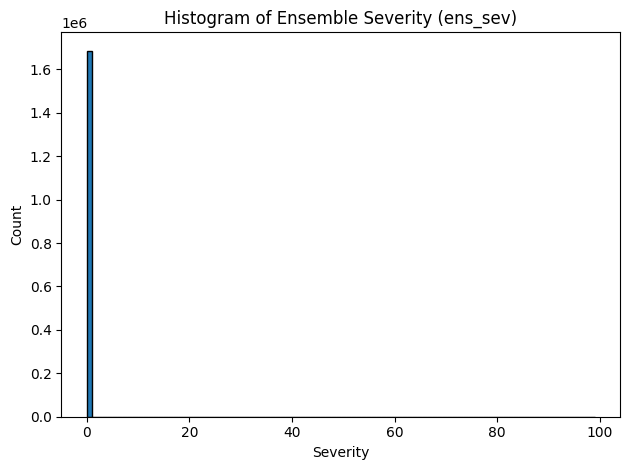

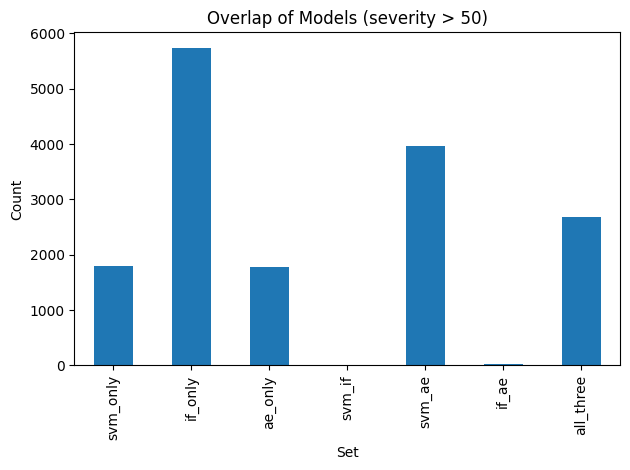

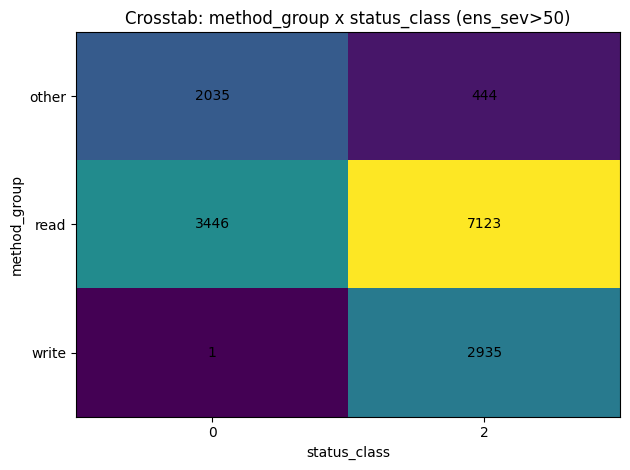

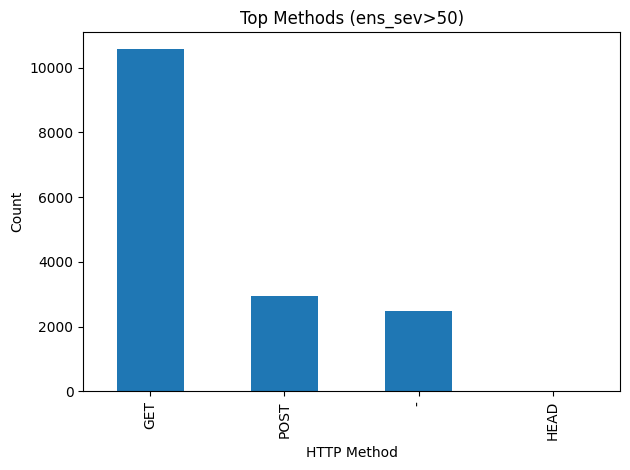

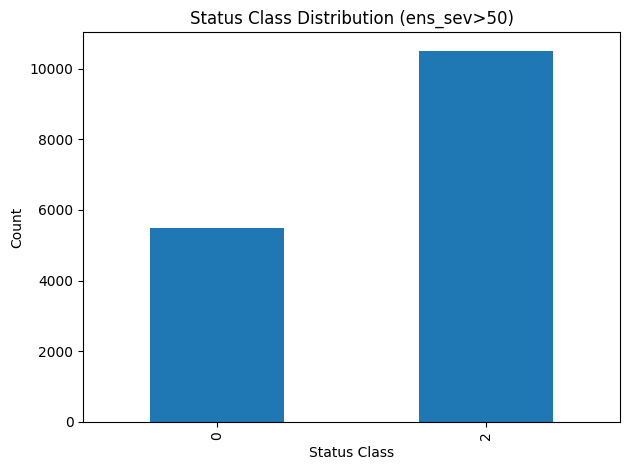


💾 Saved plots:
- /content/out/plot_hist_ensemble_severity.png
- /content/out/plot_bar_overlap_gt50.png
- /content/out/plot_heatmap_method_status_gt50.png
- /content/out/plot_bar_methods_gt50.png
- /content/out/plot_bar_statusclass_gt50.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
# 🧱 Cell 9 — Quick Visuals (matplotlib only) + Downloads
!pip -q install pandas numpy matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUT_DIR = Path("/content/out") if Path("/content").exists() else Path("./out")

# --- Load main and helper CSVs produced in Cell 8
final_csv    = OUT_DIR / "ensemble_max_severity.csv"
triage_csv   = OUT_DIR / "ensemble_max_severity_gt50.csv"
top50_csv    = OUT_DIR / "ensemble_top50.csv"
overlap_csv  = OUT_DIR / "ensemble_overlap_counts.csv"
crosstab_csv = OUT_DIR / "ensemble_crosstab_method_status_gt50.csv"

for p in [final_csv, overlap_csv, crosstab_csv]:
    assert p.exists(), f"Missing {p}. Run Cell 8 first."

final_df    = pd.read_csv(final_csv, dtype=str)
overlap_df  = pd.read_csv(overlap_csv, index_col=0)
crosstab_df = pd.read_csv(crosstab_csv, index_col=0)

# Ensure numeric for severity to plot correctly
for col in ["svm_sev","if_sev","ae_sev","ens_sev"]:
    if col in final_df.columns:
        final_df[col] = pd.to_numeric(final_df[col], errors="coerce").fillna(0).astype(int)

# ----------------------------
# 1) Histogram of ensemble severity
# ----------------------------
plt.figure()
final_df["ens_sev"].plot(kind="hist", bins=100, edgecolor="black")
plt.title("Histogram of Ensemble Severity (ens_sev)")
plt.xlabel("Severity")
plt.ylabel("Count")
hist_path = OUT_DIR / "plot_hist_ensemble_severity.png"
plt.tight_layout()
plt.savefig(hist_path, dpi=150)
plt.show()

# ----------------------------
# 2) Bar chart: overlap counts for severity>50
# ----------------------------
plt.figure()
overlap_df["count"].plot(kind="bar")
plt.title("Overlap of Models (severity > 50)")
plt.xlabel("Set")
plt.ylabel("Count")
bar_overlap_path = OUT_DIR / "plot_bar_overlap_gt50.png"
plt.tight_layout()
plt.savefig(bar_overlap_path, dpi=150)
plt.show()

# ----------------------------
# 3) Heatmap-like visualization: method_group x status_class (ens>50)
# ----------------------------
# Convert to numpy for imshow; create ticks from index/columns
data = crosstab_df.fillna(0).to_numpy()
plt.figure()
plt.imshow(data, aspect="auto")
plt.title("Crosstab: method_group x status_class (ens_sev>50)")
plt.xlabel("status_class")
plt.ylabel("method_group")
# x ticks as columns, y ticks as index
plt.xticks(ticks=np.arange(crosstab_df.shape[1]), labels=list(crosstab_df.columns), rotation=0)
plt.yticks(ticks=np.arange(crosstab_df.shape[0]), labels=list(crosstab_df.index))
# annotate cells
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        plt.text(j, i, str(int(data[i, j])), ha="center", va="center")
heatmap_path = OUT_DIR / "plot_heatmap_method_status_gt50.png"
plt.tight_layout()
plt.savefig(heatmap_path, dpi=150)
plt.show()

# ----------------------------
# 4) Bar chart: Top 10 methods and status_class in severe>50
# ----------------------------
tri = pd.read_csv(triage_csv, dtype=str) if triage_csv.exists() else final_df[final_df["ens_sev"]>50].copy()

# methods
plt.figure()
tri["http.request.method"].fillna("UNKNOWN").str.upper().value_counts().head(10).plot(kind="bar")
plt.title("Top Methods (ens_sev>50)")
plt.xlabel("HTTP Method")
plt.ylabel("Count")
bar_methods_path = OUT_DIR / "plot_bar_methods_gt50.png"
plt.tight_layout()
plt.savefig(bar_methods_path, dpi=150)
plt.show()

# status_class (derive if missing)
if "status_class" not in tri.columns:
    sc = pd.to_numeric(tri["http.response.status_code"].str.replace(r"[^\d]","",regex=True), errors="coerce").fillna(0).astype(int)
    tri["status_class"] = (sc // 100).astype(int)

plt.figure()
tri["status_class"].value_counts().sort_index().plot(kind="bar")
plt.title("Status Class Distribution (ens_sev>50)")
plt.xlabel("Status Class")
plt.ylabel("Count")
bar_status_path = OUT_DIR / "plot_bar_statusclass_gt50.png"
plt.tight_layout()
plt.savefig(bar_status_path, dpi=150)
plt.show()

print("\n💾 Saved plots:")
for p in [hist_path, bar_overlap_path, heatmap_path, bar_methods_path, bar_status_path]:
    print("-", p)

# --- Quick download in Colab
try:
    from google.colab import files
    for p in [hist_path, bar_overlap_path, heatmap_path, bar_methods_path, bar_status_path]:
        files.download(str(p))
except Exception:
    print("\nℹ️ If not in Colab, fetch files from:", OUT_DIR)


In [28]:
# 🧱 Cell 10 — Upload ZIP → Extract main CSV (unique run) → Score with EXISTING MODELS → Export Excel/CSV
!pip -q install numpy pandas scikit-learn pyarrow joblib openpyxl
!pip -q install "tensorflow>=2.17,<2.21"

import os, io, zipfile, math, gc, re, time, uuid
import numpy as np
import pandas as pd
from pathlib import Path
import joblib
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import OneHotEncoder, RobustScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.losses import MeanSquaredError

print("TensorFlow:", tf.__version__)

# --- Paths ---
ART_DIR = Path("/content/artifacts") if Path("/content").exists() else Path("./artifacts")
OUT_DIR = Path("/content/out") if Path("/content").exists() else Path("./out")
OUT_DIR.mkdir(exist_ok=True, parents=True)

# --- Require artifacts & models ---
ohe_path    = ART_DIR / "ohe.joblib"
scaler_path = ART_DIR / "scaler.joblib"
svm_path    = OUT_DIR / "svm_model.joblib"
if_path     = OUT_DIR / "iforest_model.joblib"
ae_path     = OUT_DIR / "ae_model.h5"

missing_files = [p for p in [ohe_path, scaler_path, svm_path, if_path, ae_path] if not p.exists()]
if missing_files:
    raise FileNotFoundError("❌ Missing required models/artifacts:\n" + "\n".join(str(p) for p in missing_files))

# --- Upload ZIP and pick the largest CSV (unique run folder) ---
def upload_zip_and_extract_unique():
    from google.colab import files
    print("📦 Upload your ZIP file (with the 11 Zeek HTTP base columns)...")
    up = files.upload()
    if not up:
        raise RuntimeError("No file uploaded.")
    fname = list(up.keys())[0]
    zpath = OUT_DIR / fname
    with open(zpath, "wb") as f:
        f.write(up[fname])
    print(f"✅ Uploaded ZIP: {fname}")

    # unique folder for each run
    run_dir = OUT_DIR / "incoming_zip" / f"run_{int(time.time())}_{uuid.uuid4().hex[:6]}"
    run_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zpath, "r") as zf:
        zf.extractall(run_dir)
    csvs = list(run_dir.rglob("*.csv"))
    if not csvs:
        raise RuntimeError("No CSV files found in ZIP.")
    csvs.sort(key=lambda x: x.stat().st_size, reverse=True)
    main_csv = csvs[0]
    print(f"📄 Using largest CSV: {main_csv.name} ({main_csv.stat().st_size:,} bytes)")
    return main_csv

NEW_CSV = upload_zip_and_extract_unique()

# --- Read base CSV ---
base_cols = [
    "@timestamp",
    "http.request.method",
    "http.response.status_code",
    "http.version",
    "http.response.body.bytes",
    "user_agent.original",
    "url.path",
    "url.domain",
    "destination.ip",
    "destination.port",
    "source.ip",
]
df = pd.read_csv(NEW_CSV, dtype=str, engine="python", on_bad_lines="skip")
missing = [c for c in base_cols if c not in df.columns]
if missing:
    raise ValueError(f"❌ Missing required columns: {missing}")
base_df = df[base_cols].copy()
print("✅ Loaded CSV:", base_df.shape)

# --- Feature engineering (same as training) ---
def to_int(s: pd.Series) -> pd.Series:
    return pd.to_numeric(
        s.fillna("").astype(str).str.replace(r"[^\d]", "", regex=True),
        errors="coerce"
    ).fillna(0).astype(int)

def ua_group_from(ua: pd.Series) -> pd.Series:
    u = ua.fillna("").astype(str).str.lower()
    is_browser = u.str.contains(r"mozilla|chrome|safari|firefox|edge")
    is_bot     = u.str.contains(r"curl|python|bot|go-http-client|wget|java|requests")
    is_empty   = u.str.strip().eq("")
    return (
        is_browser.map({True: "browser", False: None})
        .fillna(is_bot.map({True: "bot", False: None}))
        .fillna(is_empty.map({True: "empty", False: "other"}))
    )

num_frame = pd.DataFrame({
    "status_class": (to_int(base_df["http.response.status_code"]) // 100).astype("int16"),
    "response_bytes": to_int(base_df["http.response.body.bytes"]),
    "dest_port": to_int(base_df["destination.port"]),
    "uri_len": base_df["url.path"].fillna("").astype(str).str.len().astype("int32"),
    "http_version": pd.to_numeric(
        base_df["http.version"].fillna("").str.extract(r"(\d+(?:\.\d+)?)", expand=False),
        errors="coerce"
    ).fillna(0.0).astype("float32"),
}, index=base_df.index)

cat_frame = pd.DataFrame({
    "method": base_df["http.request.method"].fillna("UNKNOWN").astype(str).str.upper(),
    "ua_group": ua_group_from(base_df["user_agent.original"]),
}, index=base_df.index)

# --- Transform with OHE & Scaler ---
ohe = joblib.load(ohe_path)
scaler = joblib.load(scaler_path)
X_cat = ohe.transform(cat_frame)
X_num = scaler.transform(num_frame.astype(np.float32))
X = np.hstack([X_num, X_cat]).astype(np.float32)

# ⬇️ بی‌اثر کردن url.path (uri_len)
URI_LEN_COL = 3
X[:, URI_LEN_COL] = 0.0
print("🧱 Features ready:", X.shape, " — url.path set to 0-weight")

# --- Load models ---
svm = joblib.load(svm_path)
iforest = joblib.load(if_path)
def load_autoencoder_safe(path: Path):
    try:
        return keras.models.load_model(str(path), compile=False)
    except TypeError:
        return keras.models.load_model(str(path), custom_objects={"mse": MeanSquaredError()}, compile=False)
ae = load_autoencoder_safe(ae_path)
print("✅ Models loaded.")

# --- Helper funcs ---
def percentile_ranks(x):
    order = np.argsort(x)
    ranks = np.empty_like(order, dtype=np.float64)
    ranks[order] = np.arange(len(x), dtype=np.float64)
    return ranks / max(len(x)-1, 1)

def map_severity(p):
    p = np.clip(p, 0.0, 1.0)
    hi99 = 0.99; top = 1.0 - 0.00003
    sev = np.zeros_like(p, dtype=np.int16)
    sev[p >= top] = 99
    mid = (p > hi99) & (p < top)
    sev[mid] = 1 + np.floor((p[mid]-hi99)/(top-hi99)*98.0).astype(np.int16)
    return sev

# --- Scoring ---
svm_raw = -svm.decision_function(X).astype(np.float64)
svm_pct = percentile_ranks(svm_raw); svm_sev = map_severity(svm_pct)

if_raw = -iforest.score_samples(X).astype(np.float64)
if_pct = percentile_ranks(if_raw); if_sev = map_severity(if_pct)

errs = np.empty(X.shape[0], dtype=np.float64)
bs = 4096
for i in range(0, X.shape[0], bs):
    sl = slice(i, min(i+bs, X.shape[0]))
    Xb = X[sl]
    Xp = ae.predict(Xb, batch_size=bs, verbose=0)
    errs[sl] = np.mean(np.square(Xb - Xp), axis=1)
ae_raw = errs
ae_pct = percentile_ranks(ae_raw); ae_sev = map_severity(ae_pct)

ens_pct = np.maximum.reduce([svm_pct, if_pct, ae_pct])
ens_sev = map_severity(ens_pct)

# --- Build result & export ---
result = base_df.copy()
for k, v in dict(
    svm_raw=svm_raw, if_raw=if_raw, ae_raw=ae_raw,
    svm_pct=svm_pct, if_pct=if_pct, ae_pct=ae_pct,
    svm_sev=svm_sev, if_sev=if_sev, ae_sev=ae_sev,
    ens_pct=ens_pct, ens_sev=ens_sev
).items():
    result[k] = v

danger = result[result["ens_sev"] > 50].copy()

xlsx_path = OUT_DIR / "new_file_scored_from_zip.xlsx"
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as xw:
    pd.DataFrame({
        "rows_total": [len(result)],
        "rows_danger_ens_gt50": [len(danger)],
        "pct_nonzero_ens": [float((result["ens_sev"]>0).mean()*100)],
        "count_ens_99": [int((result["ens_sev"]==99).sum())],
    }).to_excel(xw, sheet_name="summary", index=False)
    danger.to_excel(xw, sheet_name="danger_ens_gt50", index=False)
    k = max(1, int(math.ceil(result.shape[0]*0.00003)))
    result.nlargest(k, "ens_pct").to_excel(xw, sheet_name="top_0_003pct", index=False)

csv_out = OUT_DIR / "new_file_scored_from_zip.csv"
result.to_csv(csv_out, index=False)

print("\n✅ Scoring complete.")
print(f"💾 Excel saved: {xlsx_path}")
print(f"💾 CSV saved:   {csv_out}")

# --- Download (Colab) ---
try:
    from google.colab import files
    files.download(str(xlsx_path))
    files.download(str(csv_out))
except Exception:
    print("\nℹ️ If not in Colab, fetch files from:", OUT_DIR)


TensorFlow: 2.19.0
📦 Upload your ZIP file (with the 11 Zeek HTTP base columns)...


Saving Untitled Discover session (25).zip to Untitled Discover session (25) (2).zip
✅ Uploaded ZIP: Untitled Discover session (25) (2).zip
📄 Using largest CSV: Untitled Discover session (25).csv (21,459,158 bytes)
✅ Loaded CSV: (130002, 11)
🧱 Features ready: (130002, 40)  — url.path set to 0-weight
✅ Models loaded.

✅ Scoring complete.
💾 Excel saved: /content/out/new_file_scored_from_zip.xlsx
💾 CSV saved:   /content/out/new_file_scored_from_zip.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# 🧱 Backup all artifacts/models to Google Drive + create restore script
from pathlib import Path
import shutil, os

# --- 1️⃣ Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# --- 2️⃣ Define paths
GDRIVE_DIR = Path("/content/drive/MyDrive/zeek_models")
LOCAL_ART = Path("/content/artifacts")
LOCAL_OUT = Path("/content/out")

# --- 3️⃣ Create drive folder
GDRIVE_DIR.mkdir(parents=True, exist_ok=True)

# --- 4️⃣ Copy artifacts and models
to_copy = [
    LOCAL_ART / "ohe.joblib",
    LOCAL_ART / "scaler.joblib",
    LOCAL_OUT / "svm_model.joblib",
    LOCAL_OUT / "iforest_model.joblib",
    LOCAL_OUT / "ae_model.h5",
]
for f in to_copy:
    if f.exists():
        shutil.copy2(f, GDRIVE_DIR / f.name)
        print("✅ Copied:", f.name)
    else:
        print("⚠️ Missing:", f)

# --- 5️⃣ Create a restore script to re-link models easily later
restore_script = f"""
from pathlib import Path
import shutil, os

src = Path("/content/drive/MyDrive/zeek_models")
art = Path("/content/artifacts")
out = Path("/content/out")

art.mkdir(parents=True, exist_ok=True)
out.mkdir(parents=True, exist_ok=True)

for name in ["ohe.joblib", "scaler.joblib"]:
    src_file = src / name
    if src_file.exists():
        shutil.copy2(src_file, art / name)
        print("✅ Restored:", name)
    else:
        print("⚠️ Missing in Drive:", name)

for name in ["svm_model.joblib", "iforest_model.joblib", "ae_model.h5"]:
    src_file = src / name
    if src_file.exists():
        shutil.copy2(src_file, out / name)
        print("✅ Restored:", name)
    else:
        print("⚠️ Missing in Drive:", name)

print("\\n🎯 All artifacts/models restored. Now you can directly run Cell 10 to score new ZIP files.")
"""

restore_path = GDRIVE_DIR / "cell10_ready.py"
restore_path.write_text(restore_script)
print(f"\n💾 Created restore script: {restore_path}")
print("\n✅ Backup complete.")
print("Next time, just run:\n\n  from google.colab import drive; drive.mount('/content/drive')\n  !python /content/drive/MyDrive/zeek_models/cell10_ready.py\n\nThen Cell 10 will be ready to run.")


Mounted at /content/drive
✅ Copied: ohe.joblib
✅ Copied: scaler.joblib
✅ Copied: svm_model.joblib
✅ Copied: iforest_model.joblib
✅ Copied: ae_model.h5

💾 Created restore script: /content/drive/MyDrive/zeek_models/cell10_ready.py

✅ Backup complete.
Next time, just run:

  from google.colab import drive; drive.mount('/content/drive')
  !python /content/drive/MyDrive/zeek_models/cell10_ready.py

Then Cell 10 will be ready to run.


In [ ]:
# 🧱 Restore models & artifacts from Google Drive (for Cell 10)
from pathlib import Path
import shutil

# 1️⃣ Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2️⃣ Source & destinations
SRC = Path("/content/drive/MyDrive/zeek_models")
ART = Path("/content/artifacts")
OUT = Path("/content/out")

ART.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

# 3️⃣ Copy artifacts
for name in ["ohe.joblib", "scaler.joblib"]:
    src_file = SRC / name
    if src_file.exists():
        shutil.copy2(src_file, ART / name)
        print("✅ Restored artifact:", name)
    else:
        print("⚠️ Missing in Drive:", name)

# 4️⃣ Copy models
for name in ["svm_model.joblib", "iforest_model.joblib", "ae_model.h5"]:
    src_file = SRC / name
    if src_file.exists():
        shutil.copy2(src_file, OUT / name)
        print("✅ Restored model:", name)
    else:
        print("⚠️ Missing in Drive:", name)

print("\n🎯 All files restored. You can now directly run Cell 10 to score new ZIP files.")
